# Event studies and diagnostics on the regime signals (Nifty)

Three questions, fixed before looking at any result. **No trading claim is made here**; this is diagnostic.

## Pre-registered hypotheses and thresholds

**H1. Do Budget days or election results coincide with regime starts?**
* Events: Union Budget presentation dates (22; Wikipedia table, with one correction: 2024 full Budget = 23 July, the page's 22 July is the Economic Survey) and Lok Sabha result days (2009, 2014, 2019, 2024). Weekend/holiday events map to the next trading day. **RBI policy dates are excluded: I could not verify a complete meeting list from any source and will not fill it from memory.**
* Regime start = (a) any change of the HMM's filtered argmax state, (b) SJM bull -> bear onset. Hit = at least one start within **[event day, +2 trading days]**.
* Null: circular-shift of the start indicator (keeps clustering and spacing), 5,000 shifts.
* 2 event types x 2 regime sources = 4 tests -> **reject chance only if p < 0.0125** (Bonferroni). Election tests have only ~3 events inside the out-of-sample window and are **underpowered by construction**: they can be reported but cannot support a claim of "reliable" coincidence.

**H2. Does the strategy's loss concentrate in transitions?**
* Transition window = the day a *held* position/regime changes (after the 2-day execution delay) plus the next 5 trading days.
* Statistic: share of total negative-return mass falling inside windows minus the share of days inside windows; circular-shift null on the window mask. For the SJM 0/1 strategy and the HMM soft overlay -> **p < 0.025** each. (Descriptive companion: mean daily strategy-minus-buy-and-hold inside vs outside windows.)

**H3. Detection lag (descriptive, no test).** For every Nifty drawdown episode of >= 10% whose peak falls inside the out-of-sample window: the trading-day lag from the price peak to the first risk-off flag, and the fraction of the eventual fall already realised at the flag and at execution (flag + 2 days). Flags: SJM bear state; HMM highest-vol state; plus two simple comparators (200-day MA below, VIX hysteresis cash) so the numbers have a reference.

Caveats: ~13 years (about 8 episodes, ~16 Budgets, 3 elections); regime-start rates are high for the HMM (mean regime ~30 days), so chance coincidence is substantial by design.


In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import regime_filter as rf, jump_model as jm, regime_allocation as ra, event_diagnostics as ed

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
px = ra.download_assets()
df = pd.DataFrame({"close": px["nifty"], "vix": px["vix"]})
feats = rf.build_features(df); idx = feats.index
ret_full = df["close"].pct_change(); ret = ret_full.reindex(idx)

res = rf.walk_forward(feats, ret, rf.WFConfig())          # primary HMM config (3 states, diag, 3y warm-up)
P = res.probs
hmm_state = P.idxmax(axis=1)
e_hmm = rf.soft_exposure(P, res.state_vol, 0.12)

X = jm.sjm_features(ret_full, 0.06).reindex(idx)
J = jm.jm_walk_forward(X, ret, jm.JMConfig(rf_annual=0.06, cost_bps=10.0))
sjm_bull = J["bull"]
pd.DataFrame({"hmm_state": hmm_state, "hmm_exposure": e_hmm, "sjm_bull": sjm_bull}).to_csv("nifty_regime_signals.csv")
print(f"HMM OOS {P.index.min().date()} -> {P.index.max().date()};  SJM OOS {sjm_bull.index.min().date()} -> {sjm_bull.index.max().date()}")
print("HMM regime changes/yr: %.1f   SJM bear onsets/yr: %.2f" % (
    ed.regime_starts(hmm_state).sum() / (len(P) / 252), ((sjm_bull.diff() == -1).sum()) / (len(sjm_bull) / 252)))

HMM OOS 2012-03-06 -> 2026-10-16;  SJM OOS 2013-03-18 -> 2026-10-16
HMM regime changes/yr: 7.9   SJM bear onsets/yr: 1.22


## H1. Events vs regime starts

In [2]:
budget = ed.map_to_trading_days(ed.BUDGET_DATES, df.index)
elect = ed.map_to_trading_days(ed.ELECTION_RESULT_DATES, df.index)
starts = {"HMM any change": ed.regime_starts(hmm_state), "SJM bear onset": (sjm_bull.diff() == -1)}
rows = []
for sname, s in starts.items():
    for ename, ev in [("Budget", budget), ("Election result", elect)]:
        r = ed.coincidence_test(s, ev, window=(0, 2), n_perm=5000, seed=1)
        rows.append({"regime start": sname, "event": ename, "events in OOS": r["n_events"], "hits": r["hits"],
                     "hit rate": r["rate"], "chance expectation": r["expected"] / max(r["n_events"], 1), "p": r["p"]})
t = pd.DataFrame(rows)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
display(t)
print("Bonferroni threshold 0.0125 ->", ["REJECT chance" if p < 0.0125 else "consistent with chance" for p in t.p])

,regime start,event,events in OOS,hits,hit rate,chance expectation,p
0,HMM any change,Budget,18,2,0.111,0.082,0.441
1,HMM any change,Election result,3,2,0.667,0.081,0.016
2,SJM bear onset,Budget,16,1,0.062,0.015,0.206
3,SJM bear onset,Election result,3,0,0.000,0.017,1.000


Bonferroni threshold 0.0125 -> ['consistent with chance', 'consistent with chance', 'consistent with chance', 'consistent with chance']


## H2. Does loss concentrate around transitions?

In [3]:
def eff_change(label_or_expo, delay=2):
    held = label_or_expo.shift(delay)
    return held.ne(held.shift()) & held.notna() & held.shift().notna()

out = []
for name, expo, lab in [("SJM 0/1", sjm_bull, sjm_bull), ("HMM soft", e_hmm, hmm_state)]:
    r_s = rf.backtest(ret.reindex(expo.index), expo.shift(1), 0.06, 10.0).dropna()
    bh = ret.reindex(r_s.index)
    mask = ed.transition_mask(eff_change(lab).reindex(r_s.index).fillna(False), 5)
    res_ = ed.loss_concentration(r_s, bh, mask, n_perm=5000, seed=2)
    out.append({"strategy": name, "transitions": int(eff_change(lab).reindex(r_s.index).sum()), **res_})
L = pd.DataFrame(out).set_index("strategy"); display(L)
print("Reading: loss_share_excess > 0 = more of the strategy's losses fall in transition windows than their share of days.")
print("Threshold p_loss < 0.025 ->", {k: ("REJECT chance" if v < 0.025 else "consistent with chance") for k, v in L.p_loss.items()})

,transitions,days_in_windows,loss_share_excess,p_loss,rel_mean_diff_bp,p_rel
strategy,,,,,,
SJM 0/1,33,0.059,-0.000,0.500,-4.338,0.248
HMM soft,111,0.154,0.008,0.258,0.472,0.625


Reading: loss_share_excess > 0 = more of the strategy's losses fall in transition windows than their share of days.
Threshold p_loss < 0.025 -> {'SJM 0/1': 'consistent with chance', 'HMM soft': 'consistent with chance'}


## H3. Detection lag on drawdown episodes (descriptive)

In [4]:
eps_all = ed.drawdown_episodes(df["close"], 0.10)
flags = {
    "SJM bear": (sjm_bull == 0),
    "HMM stress (S2)": (hmm_state == "S2"),
    "200d MA below": (jm.ma_exposure(df["close"]) == 0),
    "VIX hysteresis cash": (jm.vix_hysteresis_exposure(df["vix"]) == 0),
}
oos_start = min(sjm_bull.index.min(), P.index.min())
eps = eps_all[eps_all.peak >= oos_start].reset_index(drop=True)
print("Episodes (>=10% peak-to-trough) with peak in the OOS window:")
display(eps.assign(depth=eps.depth.round(3)))
summ = {}
tables = {}
for name, fl in flags.items():
    fl = fl.reindex(df.index).fillna(False)
    tbl = ed.detection_lag(df["close"], fl, eps, delay=2); tables[name] = tbl
    summ[name] = {"episodes flagged": int(tbl.flag_date.notna().sum()), "of": len(tbl),
                  "median lag (days)": tbl.lag_days.median(), "median fall done at flag": tbl.share_of_fall_at_flag.median(),
                  "median fall done at exec (+2d)": tbl.share_of_fall_at_exec.median(),
                  "flag already on at peak": int(tbl.active_at_peak.sum())}
display(pd.DataFrame(summ).T)
print("\nPer-episode detail, SJM bear:"); display(tables["SJM bear"]); print("Per-episode detail, HMM stress (S2):"); display(tables["HMM stress (S2)"])

Episodes (>=10% peak-to-trough) with peak in the OOS window:


,peak,trough,recovery,depth,peak_to_trough_days
0,2015-03-03,2016-02-25,2017-03-14,-0.225,227
1,2018-01-29,2018-03-23,2018-07-24,-0.102,37
2,2018-08-28,2018-10-26,2019-04-16,-0.146,39
3,2019-06-03,2019-09-19,2019-11-27,-0.114,73
4,2020-01-14,2020-03-23,2020-11-09,-0.384,47
5,2021-10-18,2022-06-17,2022-11-24,-0.172,166
6,2024-09-26,2025-03-04,2026-01-02,-0.158,107
7,2026-01-02,2026-10-08,NaT,-0.156,187


,episodes flagged,of,median lag (days),median fall done at flag,median fall done at exec (+2d),flag already on at peak
SJM bear,7.000,8.000,15.000,0.323,0.249,2.000
HMM stress (S2),4.000,8.000,66.500,0.574,0.562,0.000
200d MA below,8.000,8.000,33.000,0.658,0.591,0.000
VIX hysteresis cash,7.000,8.000,17.000,0.357,0.381,2.000



Per-episode detail, SJM bear:


,peak,trough,depth,flag_date,lag_days,fall_at_flag,share_of_fall_at_flag,share_of_fall_at_exec,active_at_peak
0,2015-03-03,2016-02-25,-0.225,2015-03-26,16.000,-0.073,0.323,0.249,False
1,2018-01-29,2018-03-23,-0.102,2018-02-19,14.000,-0.068,0.664,0.647,False
2,2018-08-28,2018-10-26,-0.146,2018-09-24,17.000,-0.066,0.451,0.401,False
3,2019-06-03,2019-09-19,-0.114,2019-07-10,26.000,-0.049,0.426,0.387,False
4,2020-01-14,2020-03-23,-0.384,2020-02-04,15.000,-0.031,0.081,0.047,False
5,2021-10-18,2022-06-17,-0.172,2021-10-18,0.000,0.000,-0.000,0.066,True
6,2024-09-26,2025-03-04,-0.158,None,NaN,NaN,NaN,NaN,False
7,2026-01-02,2026-10-08,-0.156,2026-01-02,0.000,0.000,-0.000,0.037,True


Per-episode detail, HMM stress (S2):


,peak,trough,depth,flag_date,lag_days,fall_at_flag,share_of_fall_at_flag,share_of_fall_at_exec,active_at_peak
0,2015-03-03,2016-02-25,-0.225,2015-08-24,107.000,-0.132,0.586,0.595,False
1,2018-01-29,2018-03-23,-0.102,None,NaN,NaN,NaN,NaN,False
2,2018-08-28,2018-10-26,-0.146,None,NaN,NaN,NaN,NaN,False
3,2019-06-03,2019-09-19,-0.114,None,NaN,NaN,NaN,NaN,False
4,2020-01-14,2020-03-23,-0.384,2020-02-28,32.000,-0.094,0.244,0.223,False
5,2021-10-18,2022-06-17,-0.172,2022-02-24,90.000,-0.121,0.700,0.529,False
6,2024-09-26,2025-03-04,-0.158,None,NaN,NaN,NaN,NaN,False
7,2026-01-02,2026-10-08,-0.156,2026-03-09,43.000,-0.087,0.562,0.601,False


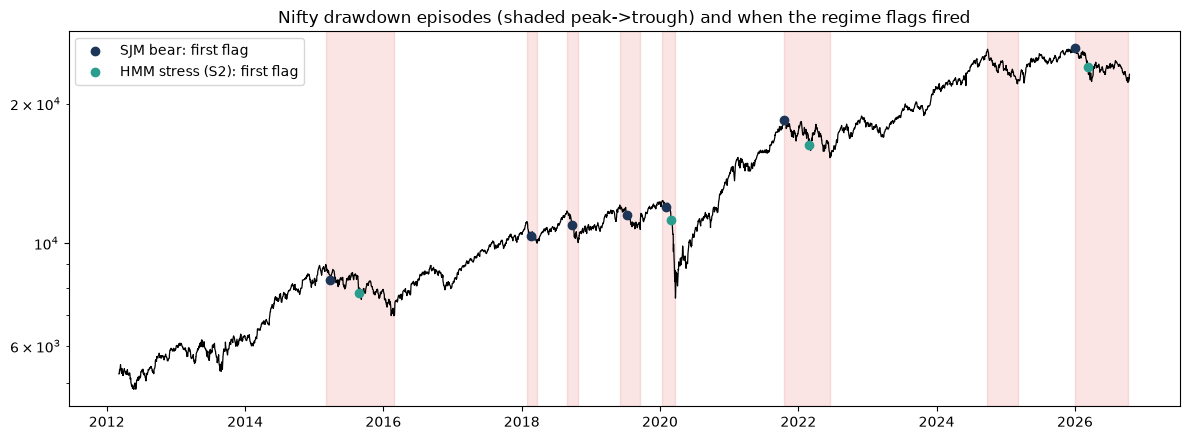

In [5]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(df["close"].loc[oos_start:], color="black", lw=0.9); ax.set_yscale("log")
for _, e in eps.iterrows(): ax.axvspan(e.peak, e.trough, color="#d62828", alpha=0.12)
for name, c in [("SJM bear", "#1d3557"), ("HMM stress (S2)", "#2a9d8f")]:
    fd = pd.to_datetime(tables[name].flag_date.dropna()); ax.scatter(fd, df["close"].reindex(fd), color=c, s=36, zorder=5, label=f"{name}: first flag")
ax.legend(); ax.set_title("Nifty drawdown episodes (shaded peak->trough) and when the regime flags fired")
plt.tight_layout(); plt.show()

## Conclusions

**H1, events vs regime starts: no evidence.** None of the four tests rejects chance at the Bonferroni threshold (0.0125).
* Budget days: HMM regime changes in 2 of 18 events (11% vs ~8% expected by chance, p = 0.44); SJM bear onsets in 1 of 16 (p = 0.21).
* Election results: the HMM changed state within 2 days of 2 of the 3 in-sample results (p = 0.016, above the 0.0125 threshold; n = 3 is far too small to support a claim). The SJM had none (0 of 3).
* RBI policy dates were **not tested**: no verifiable date list was available and none was invented.

**H2, loss concentration in transitions: no evidence.** SJM 0/1 (33 transitions, 5.9% of days in windows): loss share vs days share -0.000, p = 0.50. HMM soft (111 transitions, 15.4% of days): +0.008, p = 0.26. Strategy-minus-buy-and-hold is not significantly different inside transition windows (p = 0.25, 0.63). Power is limited, especially for the SJM's 33 transitions, but there is no hint that losses cluster around switches.

**H3, detection lag (8 drawdown episodes >= 10%, peaks 2015-2026):**

| Flag | Episodes flagged | Median lag (days) | Median share of fall done at flag / at execution (+2d) |
|---|---|---|---|
| SJM bear | 7 / 8 | 15 | 32% / 25% |
| HMM highest-vol state (S2) | 4 / 8 | 66 | 57% / 56% |
| 200-day MA below | 8 / 8 | 33 | 66% / 59% |
| VIX hysteresis (cash) | 7 / 8 | 17 | 36% / 38% |

* **The HMM, used as a stress flag, is coarse and late**, which turns the earlier "tracked coarsely" into numbers: it missed half the episodes and, when it fired, a median of about 57% of the fall had already happened.
* **The SJM is about as fast as the VIX rule and about twice as fast as a 200-day MA**. Two of its seven flags were already on at the price peak (Oct 2021, Jan 2026), so those are coincidences, not detections. For the five true detections the median lag is 16 days, 43% of the fall done at the flag and 39% at execution.
* **Covid (Jan 2020 peak, -38%):** the SJM flagged on 4 Feb 2020 after only a 3% decline, so 95% of the fall remained after execution. That is the best case in the table, but it was triggered by a small early-2020 dip three weeks before the crash, so it should be read as favourable timing, not foresight.
* **A miss to remember:** the Sep 2024 to Mar 2025 episode (-15.8%) was never flagged by the SJM.

**Overall:** neither regime signal lines up with dated macro events or concentrates its losses in transitions. Regime labels earn their keep here as a dated list of episodes and a measured lag, and the SJM's lag (about 2 to 3 weeks, roughly 40% of the fall gone by the time it trades) is the number to report.
